# Image Processing Pipeline & Required Libraries 

Libraries used for patch extraction, ROI filtering, stain normalisation, nuclei
scoring, dataset sampling, and train/validation/test splitting.

```
Folder images
        ↓
Patch Filtering and Extraction
        ↓
Data Selection and Balancing 
        ↓
Stain normalisation
        ↓
Dataset splitting 
        ↓
Upload Dataset to  
```

| Library | Purpose |
|---------|---------|
| `os` | Read folders, file names, and paths |
| `shutil` | Copy, move, delete, and zip files |
| `random` | Shuffle and sample images reproducibly |
| `defaultdict` | Group images or patches by class/slide |
| `PIL.Image` | Open, convert, resize, crop, and save images |
| `numpy` | Convert images to arrays and calculate ratios |
| `cv2` | HSV conversion and image filtering |
| `histolab.scorer.NucleiScorer` | Score patches based on nuclei content |
| `histolab.tile.Tile` | Wrap image patches for Histolab scoring |
| `matplotlib.pyplot` | Display images, masks, and patch examples |
| `splitfolders` | Split dataset into train, validation, and test folders |
| `torch` | Tensor backend used for stain normalisation |
| `torchstain` | Apply Macenko stain normalisation |


In [11]:
!pip install torchstain


Defaulting to user installation because normal site-packages is not writeable


In [12]:
!pip install split-folders

Defaulting to user installation because normal site-packages is not writeable


In [13]:
!pip install openslide-bin

Defaulting to user installation because normal site-packages is not writeable


In [14]:
!pip install histolab --no-deps
!pip install large-image-source-tiff scikit-image>=0.19 numpy pillow

Defaulting to user installation because normal site-packages is not writeable


In [15]:
!pip install opencv-python

Defaulting to user installation because normal site-packages is not writeable


In [16]:
import os
import shutil
import random
from collections import defaultdict
from PIL import Image
import numpy as np
import cv2                          # pip install opencv-python
from histolab.scorer import NucleiScorer
from histolab.tile import Tile
from PIL import Image
import matplotlib.pyplot as plt

import splitfolders
import torch, torchstain

In [17]:
import openslide
print(openslide.__version__)

1.4.6


## Patch Filtering and Extraction

This cell processes whole-tissue images by extracting fixed-size patches and filtering them based on tissue/nuclei content using Histolab's `NucleiScorer`.

### Pipeline overview

1. **Resize** input image to the target microns-per-pixel (MPP).
2. **Tile** the image into overlapping patches using a sliding window.
3. **Score** each patch with `NucleiScorer` to measure hematoxylin (nuclei) content.
4. **Filter** patches: keep those above the score threshold, drop the rest.
5. **Save** kept and dropped patches to separate folders for inspection.

### Settings

| Parameter | Value | Meaning |
|-----------|-------|---------|
| `PATCH_SIZE` | 256 | Output patch dimensions (256 × 256 pixels) |
| `TARGET_MPP` | 0.5 | Target microns-per-pixel (~20× magnification) |
| `JPG_QUALITY` | 95 | JPEG compression quality for saved patches |
| Score threshold | 0.10 | Minimum nuclei score to keep a patch |

### Filter rationale

The `NucleiScorer` (Histolab) extracts the hematoxylin channel via color deconvolution and returns the fraction of nuclei-stained pixels. Score range is [0, 1]:

- **0.0 - 0.1**: mostly background or blank tissue → drop
- **0.1 - 0.5**: typical tissue → keep
- **0.5 - 1.0**: dense cellular regions → keep

In [30]:


# =========================
# SETTINGS

PATCH_SIZE = 256
STRIDE = 256              # 128 = 50% overlap, 256 = no overlap
TARGET_MPP = 0.5
ROI_THRESHOLD = 0.8      
JPG_QUALITY = 95

# =========================      
# HSV ROI CHECK
scorer = NucleiScorer()

 
def process_class(input_dir, output_dir, droped_dir, native_mpp, class_name):
    
    os.makedirs(output_dir, exist_ok=True)
    os.makedirs(droped_dir, exist_ok=True)
    
    scale = native_mpp / TARGET_MPP

    kept = 0
    dropped = 0

    files = [  f for f in os.listdir(input_dir)  if f.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff")) ]

    print(f"\n[ Class {class_name}] {scale:.2f}")
    print(f"PATCH_SIZE={PATCH_SIZE} | STRIDE={STRIDE} | overlap={PATCH_SIZE-STRIDE}px")

    for i, fname in enumerate(files, 1):

        img_path = os.path.join(input_dir, fname)

        try:
            img = Image.open(img_path).convert("RGB")
        except Exception as e:
            print(f"Could not read {fname}: {e}")
            continue
            
        new_w = int(img.width * scale)
        new_h = int(img.height * scale)

        img = img.resize((new_w, new_h), Image.BICUBIC)
        name = os.path.splitext(fname)[0]

        for y in range(0, img.height - PATCH_SIZE + 1, STRIDE):
            for x in range(0, img.width - PATCH_SIZE + 1, STRIDE):

                patch = img.crop((
                    x,
                    y,
                    x + PATCH_SIZE,
                    y + PATCH_SIZE
                ))

                save_name = f"{name}_y{y:05d}_x{x:05d}.jpg"
                tile = Tile(patch, coords=(0, 0))
                

                if scorer(tile) > 0.1:
                    patch.save(
                        os.path.join(output_dir, save_name),
                        "JPEG", quality=JPG_QUALITY  )
                    kept += 1
                else:

                    patch.save(
                        os.path.join(droped_dir, save_name),
                        "JPEG", quality=JPG_QUALITY)
                    dropped += 1

        

    total = kept + dropped
    
    
    print("Done")
           
        

In [31]:
#   The code below to scale and patch the Breast Region of interest 

In [32]:
process_class( input_dir  = "RowDS/Br/Br Benign", output_dir = "Pre Stain/Breast Benign1", droped_dir= "Breast Benigndrop1" ,native_mpp = 0.25, class_name = "1")


[ Class 1] 0.50
PATCH_SIZE=256 | STRIDE=256 | overlap=0px
Done


In [33]:
process_class( input_dir  = "RowDS/Br/Br Invasive", output_dir = "Pre Stain/Breast Invasive1", droped_dir= "Breast Invasivedrop1" ,native_mpp = 0.25, class_name = "3")


[ Class 3] 0.50
PATCH_SIZE=256 | STRIDE=256 | overlap=0px
Done


In [34]:
process_class( input_dir  = "RowDS/Br/Br In Situ", output_dir = "Pre Stain/Breast InSitu1", droped_dir= "Breast InSitundrop1" ,native_mpp = 0.25, class_name = "3")


[ Class 3] 0.50
PATCH_SIZE=256 | STRIDE=256 | overlap=0px
Done


-----------
-----------
-----------


# Data Histogram after Pactching and removing the low score patches   

Lung cell already filter before. 

In [8]:
folder_path=[]
class_names =[]
n_imgs = []
for typename in os.listdir("Pre Stain"):
    folder_path.append (os.path.join("Pre Stain", typename))
    n_imgs.append (len(os.listdir(folder_path[-1])))
    class_names.append(typename)
print (class_names)
print (n_imgs)
print ("------------------------------------------------------")
print(f"The Total Number of patches is  {sum(n_imgs)}" )

['Breast Benign', 'Breast InSitu', 'Breast Invasive', 'LUGAD', 'SCC']
[36038, 39590, 41534, 57553, 55313]
------------------------------------------------------
The Total Number of patches is  230028


Text(0.5, 1.0, 'Patch Histogram')

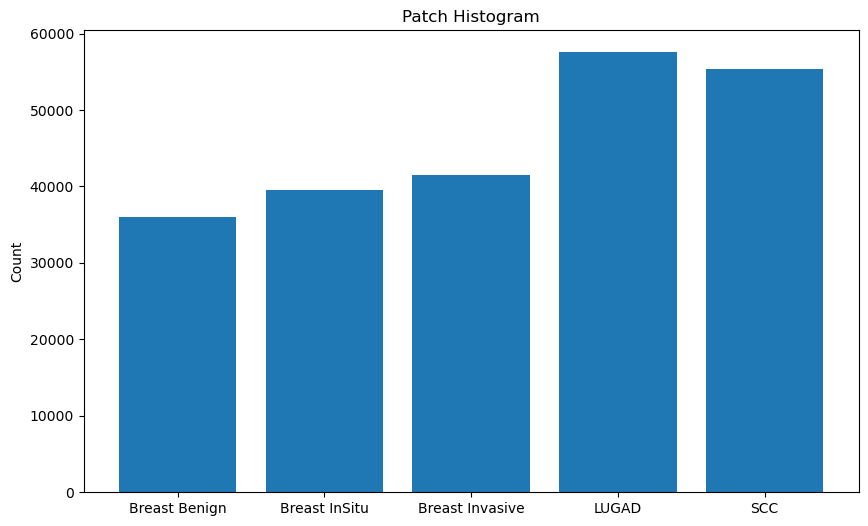

In [9]:
plt.figure(figsize=(10,6))
plt.bar(class_names,n_imgs,)
plt.ylabel("Count")
plt.title("Patch Histogram")

-----------
-----------
-----------


# Class Balancing via Slide-Aware Undersampling

## Why undersample

Two reasons motivate this step:

**1. Computational constraints.** Training on the full dataset across multiple stages (Stage 1 head, Stage 2 fine-tune, multiple architectures for comparison) is expensive in time and GPU memory. A capped dataset trains faster while still being representative.

**2. Class imbalance.** Different classes have different numbers of patches. Larger classes can dominate the loss gradient, biasing the model toward majority predictions. Capping all classes to the same size produces a balanced training distribution where every class contributes equally.




| Parameter | Value | Meaning |
|-----------|-------|---------|
| `MAX_PER_CLASS` | 20000 | Maximum patches kept per class |
| `SOURCE_DIR` | `Dataset Dir` | Original full dataset |
| `DEST_DIR` | `.../Pre Stain` | Balanced subset (output) |


## Output

The destination folder mirrors the source structure, with each class capped at `MAX_PER_CLASS`:

In [249]:


MAX_PER_CLASS = 20000
random.seed(42)
SOURCE_DIR = "Pre Stain"
DEST_DIR   = "Pre StainData_20k"
os.makedirs(DEST_DIR, exist_ok=True)

valid_ext = (".png", ".jpg", ".jpeg", ".tif", ".tiff")

print("Slide-aware undersampling:")

for class_name in os.listdir(SOURCE_DIR):

    source_class = os.path.join(SOURCE_DIR, class_name)
    dest_class   = os.path.join(DEST_DIR, class_name)

    if not os.path.isdir(source_class):
        continue

    os.makedirs(dest_class, exist_ok=True)

    files = [ f for f in os.listdir(source_class) if f.lower().endswith(valid_ext)]

    random.shuffle(files)

    selected = files[:MAX_PER_CLASS]

    for f in selected:
        shutil.copy2(
            os.path.join(source_class, f),
            os.path.join(dest_class, f)
        )

    print(f"{class_name}: available={len(files)} copied={len(selected)}")

Slide-aware undersampling:
Breast Benign: available=36038 copied=20000
Breast InSitu: available=39590 copied=20000
Breast Invasive: available=41534 copied=20000
LUGAD: available=57553 copied=20000
SCC: available=55313 copied=20000


In [253]:
folder_path=[]
class_names =[]
n_imgs = []
for typename in os.listdir("Pre StainData_20k"):
    folder_path.append (os.path.join("Pre StainData_20k", typename))
    n_imgs.append (len(os.listdir(folder_path[-1])))
    class_names.append(typename)
print (class_names)
print (n_imgs)
print ("------------------------------------------------------")
print(f"The Total Number of patches is  {sum(n_imgs)}" )


['Breast Benign', 'Breast InSitu', 'Breast Invasive', 'LUGAD', 'SCC']
[20000, 20000, 20000, 20000, 20000]
------------------------------------------------------
The Total Number of patches is  100000


Text(0.5, 1.0, 'Patch Histogram')

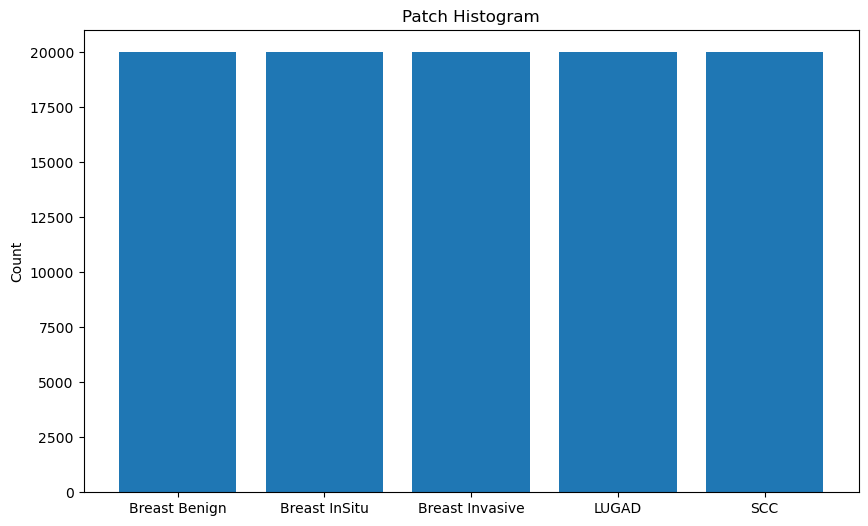

In [254]:
plt.figure(figsize=(10,6))
plt.bar(class_names,n_imgs,)
plt.ylabel("Count")
plt.title("Patch Histogram")

-----------
-----------


# Stain Normalization (Macenko Method)

Histopathology images vary in color due to differences in staining protocols, scanners, tissue preparation, and reagent batches. These color variations introduce shortcuts that can hurt model generalization across datasets.

The **Macenko method** normalizes all patches to match a single reference image's color profile, removing this source of variation.

## How it works

1. **Color deconvolution** — separates the H&E image into hematoxylin (blue/purple nuclei) and eosin (pink cytoplasm) channels
2. **Stain vector estimation** — learns the dominant stain colors from the reference image
3. **Re-staining** — maps every input image to use the reference's stain vectors

The result: all images appear as if stained in the same lab, with the same protocol, on the same day.

## Workflow

| Step | Action |
|------|--------|
| 1 | Pick one high-quality, well-stained reference patch |
| 2 | Fit the Macenko normalizer on the reference (one-time setup) |
| 3 | Apply the fitted normalizer to every patch in train/val/test |
| 4 | Save normalized patches to a parallel folder |
| 5 | Train models on the normalized data |


## Failure handling

Some patches fail normalization (e.g., near-blank patches with insufficient stain to estimate vectors from). For these, the original is copied unchanged so no patches are lost from the dataset.

Implementation: `torchstain` library (https://github.com/EIDOSLAB/torchstain

In [269]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [270]:


def normalise_folder(source_folder, output_folder):
    """
    Load a reference patch and fit the Macenko normaliser.
    The normaliser learns the stain appearance of the
    reference and maps all other patches to match it.
    Reference: Macenko et al. (2009) ISBI.
    """
    
    reference     = np.array(Image.open("Stainref.jpg").convert("RGB"))    
    normaliser    = torchstain.normalizers.MacenkoNormalizer(backend="numpy")
    normaliser.fit(reference)
  
    
   
    for subfolder  in os.listdir(source_folder):
        folder_path=[]
        folder_path= os.path.join(source_folder, subfolder )
        if not os.path.isdir(folder_path):
            continue
        os.makedirs(output_folder, exist_ok=True)
        
        output_class_folder = os.path.join(output_folder, subfolder)
        os.makedirs(output_class_folder, exist_ok=True)
        
        files   = [f for f in os.listdir(folder_path) if f.lower().endswith(('.png', '.jpg', '.tif'))]
        success = 0
        failed  = 0
        for filename in files:
            image_path  = os.path.join(folder_path, filename)
            output_path = os.path.join(output_class_folder, filename)
        
            try:
                # open image
                image = np.array(Image.open(image_path).convert("RGB"))
                # apply Macenko normalisation — returns numpy array
                normalised, _, _ = normaliser.normalize(I=image, stains=False)
    
                # save normalised patch
                Image.fromarray(normalised.astype(np.uint8)).save(output_path)
                success += 1
             
            except Exception as error:
                # some patches fail normalisation — copy original instead
               # print(f"  Failed {filename}: {error} — copying original")
                shutil.copy(image_path, output_path)  # some patches fail normalisation — copy original instead
                failed += 1
    
        print(f"Success :{success}, Failed: {failed} ")
 




In [271]:
normalise_folder("Pre StainData_20k", "Presplit")

Success :19998, Failed: 2 
Success :19998, Failed: 2 
Success :20000, Failed: 0 
Success :20000, Failed: 0 
Success :20000, Failed: 0 


-----------
---------

# Train / Validation / Test Split

## Why split the data

Machine learning models require three separate data subsets:

| Split | Ratio | Purpose |
|-------|-------|---------|
| **Train** | 70% | Model learns weights from this data |
| **Validation** | 15% | Monitors generalization during training — used for early stopping and hyperparameter tuning |
| **Test** | 15% | Final evaluation only — never seen during training or tuning |

The test set is touched **once** at the very end to report final performance. Using it during development inflates reported accuracy.

## Splitting strategy

Splitting is performed **at the patch level within each class folder** using the `split-folders` library, which:

- Preserves the class folder structure
- Ensures each split contains patches from all classes


## Settings

| Parameter | Value |
|-----------|-------|
| Input | Balanced undersampled dataset (`Datasamples/`) |
| Output | `Data_splits/` with `train/`, `val/`, `test/` subfolders |
| Ratio | 70 / 15 / 15 |


In [272]:
input_folder = 'Presplit'
output_folder = 'Data20K_splits'

splitfolders.ratio(input_folder, output=output_folder, ratio=(0.7,0.15, 0.15))
print("###")

Copying files: 100000 files [02:53, 574.95 files/s]

###


---------------------------------------------
--------------------------------------

# Save Data Splits to Google Drive (Zipped)

Zipping the dataset before saving to Google Drive is recommended because:

- **Faster upload** — one large file transfers faster than thousands of small files
- **Preserves structure** — folder hierarchy is maintained inside the zip
- **Backup** — compressed archive protects against accidental deletion of individual patches
- **Fast processing** — Google Colab's local `/content/` disk is significantly faster than Drive for I/O operations. Zip locally first, then copy the single zip file to Drive — much faster than zipping directly on Drive

##  workflow 
| Step | Location | Reason |
|------|----------|--------|
| 1. Zip the folder |  (local) | Fast local disk I/O |
| 2. Copy zip to Drive | `/content/drive/` | Single file transfer |

Zipping directly on Google Drive is slow because every file write goes through the Drive API. Zipping locally and copying once is typically **5-10× faster**.

In [18]:
import shutil

source_folder = "Data20K_splits"   # folder in current root
drive_output  = r"G:\My Drive\AIMLP2\com1r1\DataSet20K"

shutil.make_archive(
    drive_output,  # output path (no .zip)
    'zip',                                                 # format
    source_folder                                           # folder to zip
)

print("Done File transfer to Google Drive")

Done File transfer to Google Drive
